## Introduction
This project focuses on Marketing A/B Testing, which is a method used to compare two versions of a marketing campaign to determine which one performs better. The dataset contains real or simulated campaign data, including user engagement metrics, conversion rates, and campaign variations.

In this project, we will:

Assign users to control (A) and test (B) groups

Measure and compare conversion rates between groups

Conduct statistical hypothesis testing to determine significant differences

Analyze the effectiveness of different ad strategies

Draw actionable insights for optimizing future marketing campaigns

By the end of this project, you will understand how A/B testing can guide data-driven marketing decisions and improve campaign performance.

## About Content

Marketing A/B testing dataset

Marketing companies want to run successful campaigns, but the market is complex and several options can work. So normally they tun A/B tests, that is a randomized experimentation process wherein two or more versions of a variable (web page, page element, banner, etc.) are shown to different segments of people at the same time to determine which version leaves the maximum impact and drive business metrics.

The companies are interested in answering two questions:

* Would the campaign be successful?
* If the campaign was successful, how much of that success could be attributed to the ads?

With the second question in mind, we normally do an A/B test. The majority of the people will be exposed to ads (the experimental group). And a small portion of people (the control group) would instead see a Public Service Announcement (PSA) (or nothing) in the exact size and place the ad would normally be.

The idea of the dataset is to analyze the groups, find if the ads were successful, how much the company can make from the ads, and if the difference between the groups is statistically significant.

**Data dictionary:**

* Index: Row index
* user id: User ID (unique)
* test group: If "ad" the person saw the advertisement, if "psa" they only saw the public service announcement
* converted: If a person bought the product then True, else is False
* total ads: Amount of ads seen by person
* most ads day: Day that the person saw the biggest amount of ads
* most ads hour: Hour of day that the person saw the biggest amount of ads

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.stats.api as sms
from scipy.stats import shapiro, mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
import warnings
warnings.filterwarnings("ignore")



In [52]:
df = pd.read_csv("AB testing new marketing data.csv")

In [53]:
df.head()

,Unnamed: 0,user id,test group,converted,total ads,most ads day,most ads hour
0,0,1069124,ad,False,130,Monday,20
1,1,1119715,ad,False,93,Tuesday,22
2,2,1144181,ad,False,21,Tuesday,18
3,3,1435133,ad,False,355,Tuesday,10
4,4,1015700,ad,False,276,Friday,14


In [54]:
df.columns

Index(['Unnamed: 0', 'user id', 'test group', 'converted', 'total ads',
       'most ads day', 'most ads hour'],
      dtype='object')

In [55]:
df=df.drop(columns=["Unnamed: 0"],errors='ignore')
df

,user id,test group,converted,total ads,most ads day,most ads hour
0,1069124,ad,False,130,Monday,20
1,1119715,ad,False,93,Tuesday,22
2,1144181,ad,False,21,Tuesday,18
3,1435133,ad,False,355,Tuesday,10
4,1015700,ad,False,276,Friday,14
...,...,...,...,...,...,...
588096,1278437,ad,False,1,Tuesday,23
588097,1327975,ad,False,1,Tuesday,23
588098,1038442,ad,False,3,Tuesday,23
588099,1496395,ad,False,1,Tuesday,23


In [56]:
df.describe()

,user id,total ads,most ads hour
count,5.881010e+05,588101.000000,588101.000000
mean,1.310692e+06,24.820876,14.469061
std,2.022260e+05,43.715181,4.834634
min,9.000000e+05,1.000000,0.000000
25%,1.143190e+06,4.000000,11.000000
50%,1.313725e+06,13.000000,14.000000
75%,1.484088e+06,27.000000,18.000000
max,1.654483e+06,2065.000000,23.000000


In [57]:
df.info

<bound method DataFrame.info of         user id test group  converted  total ads most ads day  most ads hour
0       1069124         ad      False        130       Monday             20
1       1119715         ad      False         93      Tuesday             22
2       1144181         ad      False         21      Tuesday             18
3       1435133         ad      False        355      Tuesday             10
4       1015700         ad      False        276       Friday             14
...         ...        ...        ...        ...          ...            ...
588096  1278437         ad      False          1      Tuesday             23
588097  1327975         ad      False          1      Tuesday             23
588098  1038442         ad      False          3      Tuesday             23
588099  1496395         ad      False          1      Tuesday             23
588100  1237779         ad      False          1      Tuesday             23

[588101 rows x 6 columns]>

In [58]:
df.isnull().sum()

user id          0
test group       0
converted        0
total ads        0
most ads day     0
most ads hour    0
dtype: int64

In [59]:
df["user id"].duplicated().sum()

np.int64(0)

## Exploratory Data Analysis

In [60]:
df["test group"].value_counts()

test group
ad     564577
psa     23524
Name: count, dtype: int64

In [61]:
(df["test group"].value_counts(normalize=True) * 100).round(2)

test group
ad     96.0
psa     4.0
Name: proportion, dtype: float64

In [62]:
summary = df.groupby("test group")["converted"].agg(conversions="sum", users="count", conversion_rate="mean")
summary["conversion_rate_pct"] = (summary["conversion_rate"] * 100).round(3)
summary

,conversions,users,conversion_rate,conversion_rate_pct
test group,,,,
ad,14423,564577,0.025547,2.555
psa,420,23524,0.017854,1.785


**ads by day and hour**

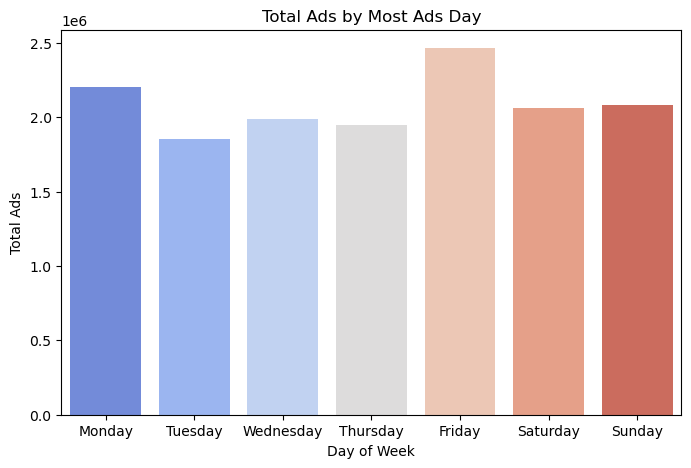

In [63]:
ads_day = df.groupby("most ads day")["total ads"].sum().reset_index()

day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
ads_day["most ads day"] = pd.Categorical(ads_day["most ads day"], categories=day_order, ordered=True)
ads_day = ads_day.sort_values("most ads day")

# Bar plot
plt.figure(figsize=(8,5))
sns.barplot(data=ads_day, x="most ads day", y="total ads", palette="coolwarm")
plt.title("Total Ads by Most Ads Day")
plt.ylabel("Total Ads")
plt.xlabel("Day of Week")
plt.show()

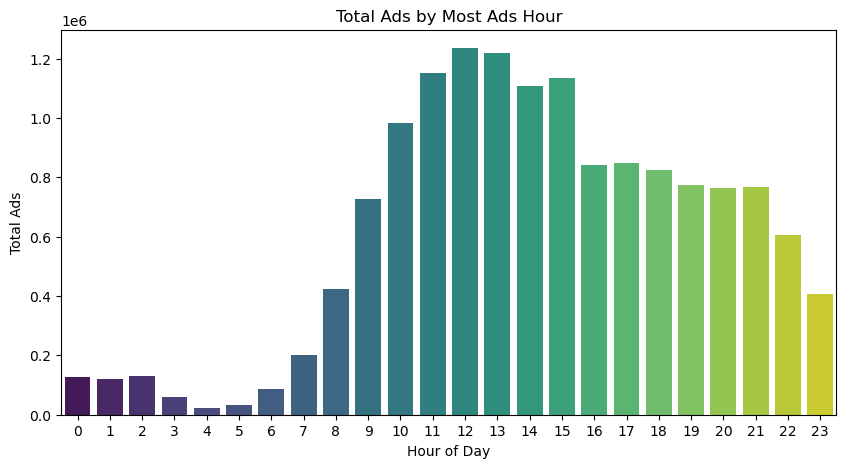

In [64]:
ads_hour = df.groupby("most ads hour")["total ads"].sum().reset_index()
plt.figure(figsize=(10,5))
sns.barplot(data=ads_hour, x="most ads hour", y="total ads", palette="viridis")
plt.title("Total Ads by Most Ads Hour")
plt.ylabel("Total Ads")
plt.xlabel("Hour of Day")
plt.show()

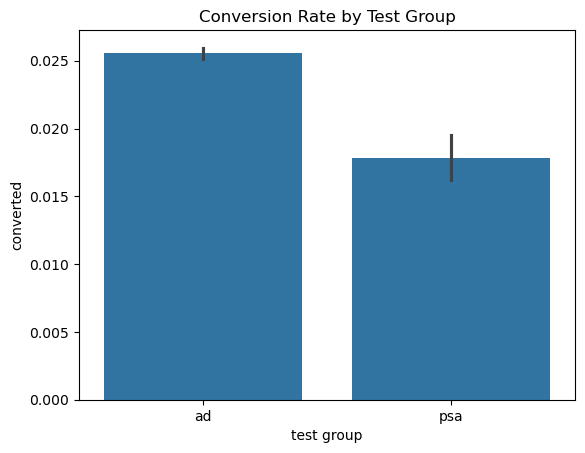

In [65]:
sns.barplot(x="test group", y="converted", data=df)
plt.title("Conversion Rate by Test Group")
plt.show()

At first glance, the conversion rate of the **ad group** appears to be higher than that of the **PSA group**. This suggests that showing advertisements may have a positive impact on user conversions.

However, this observation is based only on descriptive analysis and visualizations. In order to determine whether the difference between the two groups is statistically significant, we need to conduct a formal hypothesis test.

Therefore, the next step is to perform an A/B test using a statistical method to evaluate whether the observed difference in conversion rates is meaningful or simply due to random variation.

**Hypothesis Testing**<br>
To evaluate whether the advertisement truly increases the conversion rate, we will perform a statistical hypothesis test.<br>

**Null Hypothesis (H0):** There is no difference in conversion rates between the ad group and the PSA group.<br>

**Alternative Hypothesis (H1):** There is difference in conversion rates between the ad group and the PSA group.

To test this hypothesis, we will use a two-proportion z-test, which is commonly used to compare conversion rates between two groups in A/B testing experiments.

Assumptions for A/B Testing<br>
Before conducting the hypothesis test, it is important to verify that the assumptions required for the test are satisfied. In A/B testing, several key assumptions must be considered to ensure that the statistical results are reliable.

**Step 1: Normality Assumption**<br>
Before performing the hypothesis test, we first check whether the normality assumption is satisfied.

**H0 (Null Hypothesis):** The data follows a normal distribution.<br>
**H1 (Alternative Hypothesis):** The data does not follow a normal distribution.<br>

To evaluate this assumption, we will apply a normality test and examine whether the distribution significantly deviates from normality.

If the p-value is greater than 0.05, we fail to reject the null hypothesis and conclude that the normality assumption is satisfied. If the p-value is less than 0.05, we reject the null hypothesis and conclude that the data does not follow a normal distribution.

In [66]:
ad_group = df[df["test group"] == "ad"]["total ads"]
psa_group = df[df["test group"] == "psa"]["total ads"]

In [70]:
stat_ad, p_ad = shapiro(ad_group.sample(5000,random_state=42))
stat_psa, p_psa = shapiro(psa_group.sample(5000,random_state=42))

print("Ad group p-value:", p_ad)
print("PSA group p-value:", p_psa)

Ad group p-value: 1.6395822311369596e-79
PSA group p-value: 3.3272534219104105e-79


Normality Test Results<br>
The Shapiro-Wilk test was applied to evaluate whether the total ads variable follows a normal distribution for both groups.

* Ad group p-value: 1.63e-79
* PSA group p-value: 3.32e-79

Since the p-values are significantly smaller than 0.05, we reject the null hypothesis. This indicates that the total ads variable does not follow a normal distribution in either group.

Given the large sample size and the non-normal distribution of the data, non-parametric or proportion-based statistical methods are more appropriate for evaluating the difference between the two groups.

**Step 2: Non-Parametric Test for Total Ads**<br>
Since the normality assumption was not satisfied in Step 1, and the data is not normally distributed, we proceed with a non-parametric test.

We use the Mann-Whitney U test to compare the distributions of total ads between the ad group and the PSA group. This test does not require normality and is suitable for continuous variables that do not follow a normal distribution.

**Hypothesis for Conversion Rate**

In this A/B test, the main objective is to determine whether showing advertisements increases the conversion rate.

**Null Hypothesis (H0):** The conversion rate is the same for the ad group and the PSA group.

**Alternative Hypothesis (H1):** The conversion rate of the ad group is different from that of the PSA group.

Since the outcome variable (converted) is binary, we will use a proportion-based statistical test (Two-Proportion Z-Test) to evaluate the difference between the two groups.

In [71]:
# Mann-Whitney U testi
stat, p = mannwhitneyu(ad_group, psa_group, alternative='two-sided')

print("Mann-Whitney U statistic:", stat)
print("p-value:", p)

Mann-Whitney U statistic: 6808288222.0
p-value: 4.6909108547205694e-11


In [72]:
p_value = 4.69e-11
print(f"{p_value:.10f}")

0.0000000000


The Mann-Whitney U test was applied to compare the distribution of total ads between the ad group and the PSA group.

* Mann-Whitney U statistic: 6,808,288,222

* p-value: 4.69e-11

Since the p-value is much smaller than 0.05, we reject the null hypothesis. This indicates that the distribution of total_ads is significantly different between the ad group and the PSA group.

**Step 3: Two-Proportion Z-Test (Binary Outcome)**
* Null Hypothesis (H0): The conversion rate is the same for the ad group and the PSA group.
* Alternative Hypothesis (H1): The conversion rate of the ad group is different from that of the PSA group. (two-sided)

In [73]:
from statsmodels.stats.proportion import proportions_ztest

success = df.groupby("test group")["converted"].sum()
nobs = df.groupby("test group")["converted"].count()

# Fixed order so a positive z means ad > psa
success = success[["ad", "psa"]]
nobs = nobs[["ad", "psa"]]

# Two-Proportion Z-Test (two-sided)
z_stat, p_value = proportions_ztest(success, nobs, alternative='two-sided')

print("Z-statistic:", z_stat)
print("p-value:", p_value)

Z-statistic: 7.3700781265454145
p-value: 1.7052807161559727e-13


The Two-Proportion Z-Test was applied to compare the conversion rates of the ad group and the PSA group.

Since the p-value (1.71e-13) is much smaller than 0.05, we reject the null hypothesis. This indicates that there is a statistically significant difference in conversion rates between the ad group and the PSA group.

In other words, showing advertisements had a significant effect on increasing conversions in this experiment

## Step 4: Summary & Business Insight
| Test | Variable |	Purpose | Result | Insight |
| :--- |:--- | :--- | :--- | :--- |
| **Mann-Whitney U** | 'total_ads' (numeric) | Compare the distribution of ads seen by ad vs PSA groups | p-value = 4.69e-11 → Reject H0 | Users in the ad and PSA groups saw different numbers of ads |
| **Two-Proportion Z-Test** | 'converted' (binary) | Compare conversion rates between ad vs PSA groups | p-value = 1.71e-13 → Reject H0 | Showing ads had a significant positive effect on conversion |


In [74]:
p_ad, p_psa = success["ad"]/nobs["ad"], success["psa"]/nobs["psa"]
abs_lift = p_ad - p_psa
rel_lift = abs_lift / p_psa
ci_low, ci_high = confint_proportions_2indep(success["ad"], nobs["ad"], success["psa"], nobs["psa"], compare="diff")

print(f"Ad conversion rate:  {p_ad:.4%}")
print(f"PSA conversion rate: {p_psa:.4%}")
print(f"Absolute lift: {abs_lift*100:.3f} percentage points (95% CI: {ci_low*100:.3f} to {ci_high*100:.3f})")
print(f"Relative lift: {rel_lift:.1%}")

Ad conversion rate:  2.5547%
PSA conversion rate: 1.7854%
Absolute lift: 0.769 percentage points (95% CI: 0.587 to 0.936)
Relative lift: 43.1%


## Final Conclusion
* The ad group converted at 2.55% (14,423 of 564,577) versus 1.79% (420 of 23,524) in the PSA group.
  
**1️-EDA Insights:**
* Users in the ad group saw a higher number of total ads than the PSA group (Mann-Whitney U test confirmed this difference).
* The distribution of ads varied by day and hour, indicating peak exposure periods.

**2️- A/B Test Results:**
* The Two-Proportion Z-Test showed that conversion rates were significantly higher in the ad group (p-value = 1.71e-13).
* This demonstrates that the advertisement campaign effectively increased conversions.
* The absolute lift is about 0.77 percentage points, a relative lift of about 43% (95% CI).

**3️- Business Insight:**
* Ads are impactful: displaying advertisements significantly improves user conversion.
* Peak days and hours for ad exposure can guide future campaign optimization for maximum effectiveness.

**Overall:** The experiment provides strong statistical evidence that the advertising strategy works, both in exposure and in increasing conversions.